# Exploratory Data Analysis of Superstore Retail Sales
Objectives
1. Examine the structure and quality of the dataset.
2. Identify missing values and potential data inconsistencies.
3. Analyse sales and profit distributions.
4. Investigate monthly sales trends and seasonality.
5. Examine the relationship between discounts and profitability.
6. Develop evidence-based business recommendations.

# 1. Import required libraries

In [85]:
import pandas as pd 
import seaborn as sns
import numpy as np
import matplotlib as plt


In [4]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)

In [5]:
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)



# 2. Load the dataset

In [6]:
df = pd.read_csv("D:/Work/Datheon/superstore_sales.csv")

# 2. Initial Data Inspection
dataset's dimensions, variable names, data types and general structure.

In [9]:
#First 3 records and last 3
df.head(3)
df.head(-3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10792,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
print(f"number of records (rows): {df.shape[0]:,}")
print(f"numer of cols(variables): {df.shape[1]}")

number of records (rows): 10,800
numer of cols(variables): 21


In [21]:
#list all variables/col names
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [23]:
#Identify data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [27]:
#The Descriptive Statistics
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,10800,10001,Yes,800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order ID,10800,5015,CA-2018-100111,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1236,9/5/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2016,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
#Assess Missing Values
print(f"Missing Values",df.isnull().sum())



Missing Values Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [12]:
print(f"Missing %age", df.isnull().mean()* 100)

Missing %age Row ID          0.00
Order ID        0.00
Order Date      7.46
Ship Date       7.46
Ship Mode       7.46
Customer ID     7.46
Customer Name   7.46
Segment         7.46
Country         7.46
City            7.46
State           7.46
Postal Code     7.56
Region          7.46
Product ID      7.46
Category        7.46
Sub-Category    7.46
Product Name    7.46
Sales           7.46
Quantity        7.46
Discount        7.46
Profit          7.46
dtype: float64


## 3. Data Cleaning and Preparation
The raw dataset contains additional records that do not
conform to the main transaction structure.
These records include return-status entries and
metadata rows. They are excluded from the analytical
dataset to prevent incorrect sales calculations.
The cleaning process also includes date conversion,
data type validation and missing-value treatment.

In [13]:

# Create a working copy containing valid transactions

df_clean = df.loc[
    df["Order Date"].notna() &
    df["Sales"].notna()
].copy()

print("Original records:", len(df))
print("Clean transaction records:", len(df_clean))
print("Excluded records:", len(df) - len(df_clean))


Original records: 10800
Clean transaction records: 9994
Excluded records: 806


In [14]:

# Convert dates into datetime format

df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [16]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   str           
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9983 non-null   float64       
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [17]:

# Extract date components and create new Columns

df_clean["Order Year"] = df_clean["Order Date"].dt.year

df_clean["Order Month"] = df_clean["Order Date"].dt.month

df_clean["Year-Month"] = (
    df_clean["Order Date"].dt.to_period("M").astype(str)
)


In [18]:
# Inspecting the new variables
df_clean[
    ["Order Date", "Order Year", "Order Month", "Year-Month"]
].head(5)
#these variables will be used to investigate monthly sales trends and seasonality.

,Order Date,Order Year,Order Month,Year-Month
0,2017-11-08,2017,11,2017-11
1,2017-11-08,2017,11,2017-11
2,2017-06-12,2017,6,2017-06
3,2016-10-11,2016,10,2016-10
4,2016-10-11,2016,10,2016-10


In [19]:

# Convert numerical columns to appropriate data types

numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Postal Code"
]

for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )


In [20]:

# Check data types
df_clean.dtypes


Row ID                      str
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code             float64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                float64
Discount                float64
Profit                  float64
Order Year                int32
Order Month               int32
Year-Month                  str
dtype: object

In [21]:

# Assessing Missing Values After data Cleaning

missing_after_cleaning = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

In [22]:
#Old data du[licates 
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 504


In [23]:
#Duplicates after cleaning
print("Duplicate records:", df_clean.duplicated().sum())

Duplicate records: 0


In [24]:
# Save cleaned dataset
df_clean.to_csv(
    "../superstore_cleaned.csv",
    index=False
)

In [25]:
df_clean.shape




(9994, 24)

In [26]:
df_clean.dtypes

Row ID                      str
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code             float64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                float64
Discount                float64
Profit                  float64
Order Year                int32
Order Month               int32
Year-Month                  str
dtype: object

In [27]:
df_clean[
    ["Sales", "Quantity", "Discount", "Profit"]
].describe()

,Sales,Quantity,Discount,Profit
count,"9,994.00","9,994.00","9,994.00","9,994.00"
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,"-6,599.98"
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,"22,638.48",14.00,0.80,"8,399.98"


In [28]:
df_clean.isnull().sum().sort_values(ascending=False).head(5)

Postal Code    11
Row ID          0
Order Date      0
Order ID        0
Ship Mode       0
dtype: int64

# Commercial and Customer Sales Analysis
This section examines the overall commercial performance
of the Superstore using key sales, profitability and
customer activity indicators.

The analysis establishes baseline performance measures
that will support subsequent comparisons across product
categories, geographic regions and customer segments.

KPIs

In [95]:
# Overall business performance
total_sale = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()
profit_margin = (total_profit / total_sale) * 100




total_orders = df_clean["Order ID"].nunique()
unique_customers = df_clean["Customer ID"].nunique()
total_quantity = df_clean['Quantity'].sum()


#order analysis
average_order_value = total_sale / total_orders
average_sale_per_customer = total_sale / unique_customers



In [96]:
print(f"total_sale = {total_sale:,.2f}")
print(f"total_profit = {total_profit:,.2f}")
print(f"profit_margin = {profit_margin:.2f}%")
print(f"total_orders = {total_orders:,}")
print(f"unique_customers = {unique_customers:,}")
print(f"total_quantity = {total_quantity:,}")
print(f"average_order_value = {average_order_value:,.2f}")
print(f"average_sale_per_customer = {average_sale_per_customer:,.2f}")

total_sale = 2,297,200.86
total_profit = 286,397.02
profit_margin = 12.47%
total_orders = 5,009
unique_customers = 793
total_quantity = 37,873.0
average_order_value = 458.61
average_sale_per_customer = 2,896.85


#KPI Summary Table

In [97]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Profit Margin (%)",
        "Total Orders",
        "Unique Customers",
        "Total Quantity Sold",
        "Average Order Value",
        "Average Sales per Customer"
    ],
    "Value": [
        total_sale,
        total_profit,
        profit_margin,
        total_orders,
        unique_customers,
        total_quantity,
        average_order_value,
        average_sale_per_customer
    ]
})

kpi_summary

,Metric,Value
0,Total Sales,"2,297,200.86"
1,Total Profit,"286,397.02"
2,Profit Margin (%),12.47
3,Total Orders,"5,009.00"
4,Unique Customers,793.00
5,Total Quantity Sold,"37,873.00"
6,Average Order Value,458.61
7,Average Sales per Customer,"2,896.85"


#Customer Order Analysis

In [98]:
customer_orders = (
    df_clean.groupby("Customer ID")["Order ID"]
    .nunique()
    .reset_index(name="Number of Orders")
)
#frequency of purchasing
customer_orders["Number of Orders"].describe()

count   793.00
mean      6.32
std       2.55
min       1.00
25%       5.00
50%       6.00
75%       8.00
max      17.00
Name: Number of Orders, dtype: float64

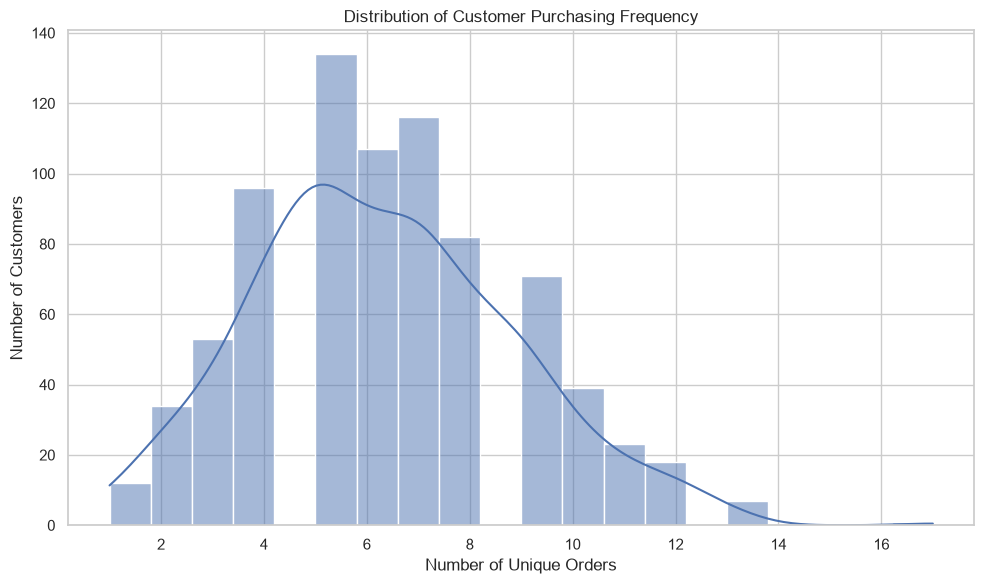

In [99]:
# Customer Order Analysis Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))

sns.histplot(
    data=customer_orders,
    x="Number of Orders",
    bins=20,
    kde=True
)

plt.title("Distribution of Customer Purchasing Frequency")
plt.xlabel("Number of Unique Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [ ]:
# Exporting KPI summary

kpi_summary.to_csv(
    "../reports/overall_kpi_summary.csv",
    index=False
)

# Exporting customer purchasing frequency

customer_orders.to_csv(
    "../reports/customer_order_frequency.csv",
    index=False
)

##Product Category Performance Analysis


This section examines the commercial performance of
the Superstore's product portfolio.

The analysis compares sales revenue, profit and profit
margins across product categories and sub-categories.

It aims to identify the product groups that contribute
most to revenue generation and profitability, while
highlighting categories that may require further
commercial investigation.

The analysis uses aggregate sales and profit measures
to support comparisons across the product portfolio.

In [101]:
#Performance By Category


In [106]:
#Aggregate Sales by Product Category

category_performance = (
    df_clean.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Number_of_Orders=("Order ID", "nunique"),
        Number_of_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)


# profit margin and sales contribution
category_performance["Profit_Margin_%"] = (
    category_performance["Total_Profit"] /
    category_performance["Total_Sales"] * 100
)

category_performance["Sales_Contribution_%"] = (
    category_performance["Total_Sales"] /
    category_performance["Total_Sales"].sum() * 100
)


category_performance.round(2)


,Category,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Number_of_Customers,Profit_Margin_%,Sales_Contribution_%
0,Furniture,"741,999.80","18,451.27","8,028.00",1764,707,2.49,32.30
1,Office Supplies,"719,047.03","122,490.80","22,906.00",3742,788,17.04,31.30
2,Technology,"836,154.03","145,454.95","6,939.00",1544,687,17.40,36.40


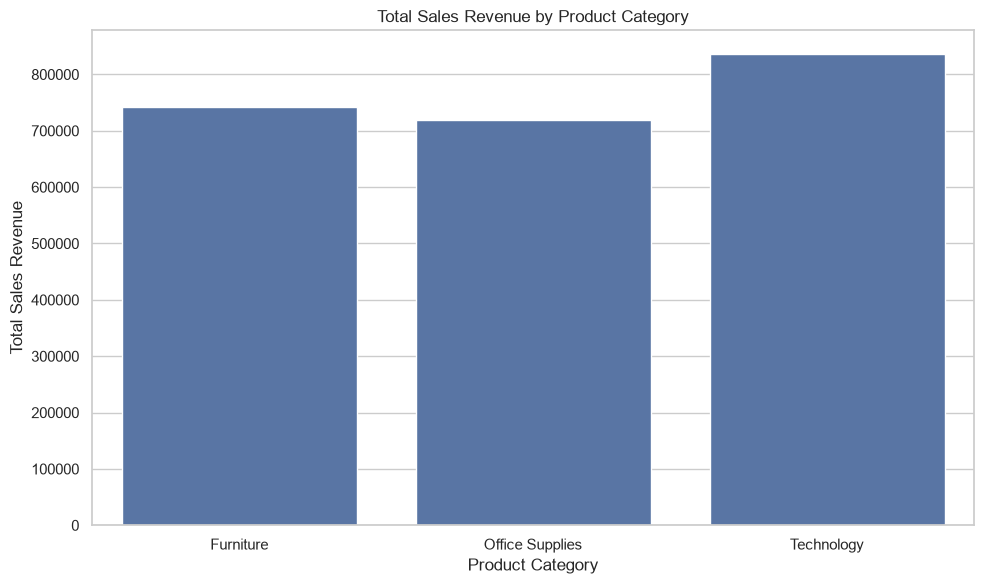

In [ ]:

# Visualize Category-wise sales revenue

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_performance,
    x="Category",
    y="Total_Sales"
)

plt.title("Total Sales Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Revenue")

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()
